ÉTAPE 1 : Importation modèle InceptionV3 

On charge le modèle pré-entrainté sur ImageNet et on retire les couches fully connected pour retirer les prédictions et mettre les notres. 

In [1]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

# Charger InceptionV3 sans la dernière couche (include_top=False)
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))


/Users/yannplouhinec/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


ÉTAPE 2 : Ajouter nos propres couches de classification 

In [2]:
x = base_model.output
x = GlobalAveragePooling2D()(x)  # Convertit la feature map 8x8x2048 en vecteur 1D
x = Dense(1024, activation='relu')(x)  # Couche dense avec 1024 neurones fully connected
predictions = Dense(2, activation='softmax')(x)  # Couche de sortie pour 2 classes

model = Model(inputs=base_model.input, outputs=predictions)

ÉTAPE 3 : Gèle des couches d'InceptionV3

On gèle les couches pré-entrainées pour garder les connaissances de notre modèle.

In [3]:
for layer in base_model.layers:
    layer.trainable = False  # Geler les couches de base pour le transfert learning

ÉTAPE 4 : Préparation de nos données

In [4]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.inception_v3 import preprocess_input

# Chemins vers les répertoires d'entraînement, de train et de validation
train_dir = os.path.join(os.getcwd(), 'chest_xray', 'train') 
val_dir = os.path.join(os.getcwd(), 'chest_xray', 'val') 

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    # rotation_range=20,       # rotation aléatoire jusqu'à 20 degrés
    # width_shift_range=0.2,   # décalage horizontal aléatoire jusqu'à 20%
    # height_shift_range=0.2,  # décalage vertical aléatoire jusqu'à 20%
    # zoom_range=0.2,          # zoom aléatoire jusqu'à 20%
    # horizontal_flip=True,    # retournement horizontal aléatoire
    # fill_mode='nearest'      # mode de remplissage pour les pixels manquants
)


train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

val_generator = train_datagen.flow_from_directory(
    val_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 5216 images belonging to 2 classes.
Found 36 images belonging to 2 classes.


ÉTAPE 5: Complier et entraîner le modèle

In [5]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Entraîner le modèle
model.fit(
    train_generator,
    epochs=5,  # Ajuster le nombre d'époques selon les besoins
    # steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=val_generator
    # validation_steps=val_generator.samples // val_generator.batch_size,
)

/Users/yannplouhinec/Library/Python/3.9/lib/python/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 141s 853ms/step - accuracy: 0.8045 - loss: 0.8087 - val_accuracy: 0.8889 - val_loss: 0.1976
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 139s 853ms/step - accuracy: 0.9470 - loss: 0.1299 - val_accuracy: 0.9167 - val_loss: 0.2350
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 133s 816ms/step - accuracy: 0.9616 - loss: 0.1018 - val_accuracy: 0.8889 - val_loss: 0.2551
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 134s 821ms/step - accuracy: 0.9667 - loss: 0.0881 - val_accuracy: 0.9167 - val_loss: 0.2174
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 137s 839ms/step - accuracy: 0.9755 - loss: 0.0689 - val_accuracy: 0.9444 - val_loss: 0.2149


In [6]:
train_eval_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Important pour la correspondance entre y_pred et y_true
)


Found 5216 images belonging to 2 classes.


In [7]:
import numpy as np

y_train_pred = model.predict(train_eval_generator)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)
y_train_true = train_eval_generator.classes

163/163 ━━━━━━━━━━━━━━━━━━━━ 134s 820ms/step


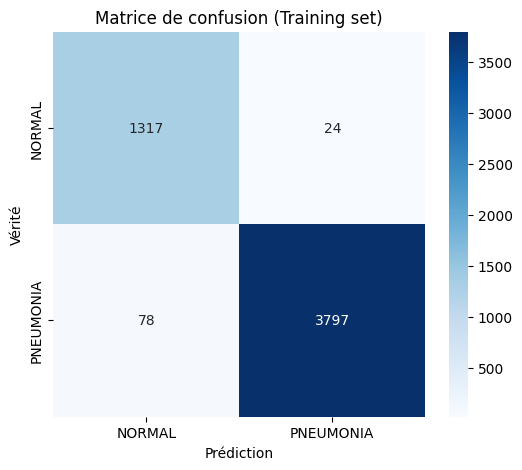

Rapport de classification sur le set d'entraînement :
              precision    recall  f1-score   support

      NORMAL       0.94      0.98      0.96      1341
   PNEUMONIA       0.99      0.98      0.99      3875

    accuracy                           0.98      5216
   macro avg       0.97      0.98      0.97      5216
weighted avg       0.98      0.98      0.98      5216



In [8]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

cm_train = confusion_matrix(y_train_true, y_train_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', xticklabels=train_eval_generator.class_indices,
            yticklabels=train_eval_generator.class_indices)
plt.title('Matrice de confusion (Training set)')
plt.xlabel('Prédiction')
plt.ylabel('Vérité')
plt.show()

print("Rapport de classification sur le set d'entraînement :")
print(classification_report(y_train_true, y_train_pred_classes, target_names=train_eval_generator.class_indices))


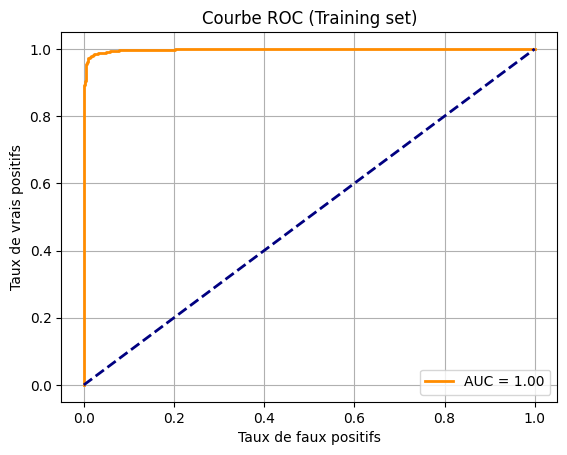

In [9]:
from sklearn.preprocessing import label_binarize

y_train_true_bin = label_binarize(y_train_true, classes=[0, 1])
fpr_train, tpr_train, _ = roc_curve(y_train_true_bin.ravel(), y_train_pred[:, 1])
roc_auc_train = auc(fpr_train, tpr_train)

plt.figure()
plt.plot(fpr_train, tpr_train, color='darkorange', lw=2, label='AUC = %0.2f' % roc_auc_train)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title("Courbe ROC (Training set)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Étape 6 : File-tuning

In [10]:
for layer in base_model.layers[-30:]:
    layer.trainable = True

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Entraîner le modèle
model.fit(
    train_generator,
    epochs=5,  # Ajuster le nombre d'époques selon les besoins
    # steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=val_generator
    # validation_steps=val_generator.samples // val_generator.batch_size,
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 152s 913ms/step - accuracy: 0.9422 - loss: 0.1579 - val_accuracy: 0.8056 - val_loss: 1.3302
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 147s 902ms/step - accuracy: 0.9784 - loss: 0.0580 - val_accuracy: 0.8889 - val_loss: 0.4179
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 148s 908ms/step - accuracy: 0.9872 - loss: 0.0328 - val_accuracy: 0.9444 - val_loss: 0.1657
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 151s 927ms/step - accuracy: 0.9958 - loss: 0.0127 - val_accuracy: 0.9444 - val_loss: 0.3155
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 149s 912ms/step - accuracy: 0.9978 - loss: 0.0075 - val_accuracy: 0.9722 - val_loss: 0.1306


Bonus : Afficher la matrice de confusion et la courbe AUC/ROC 

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 656ms/step


<Figure size 600x600 with 0 Axes>

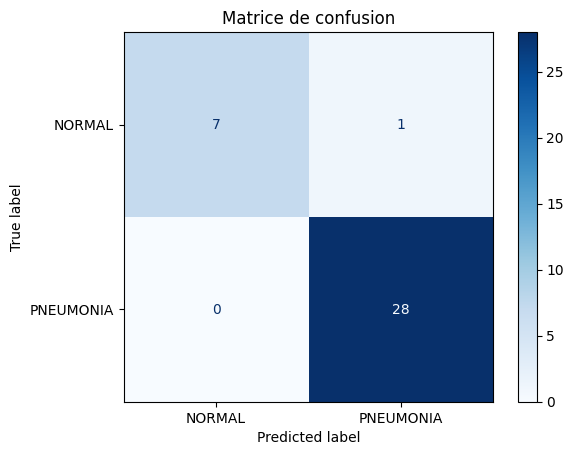

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report, roc_curve, auc, RocCurveDisplay

# Étape 1 : Prédictions sur le jeu de validation
y_pred = model.predict(val_generator)
y_pred_classes = np.argmax(y_pred, axis=1) # Indice de la classe prédite

# Étape 2 : Récupérer les vraies classes
y_true = val_generator.classes  # Classes réelles

# Étape 3 : Obtenir les noms de classes dans le bon ordre
class_names = list(val_generator.class_indices.keys())  # Noms des classes

# Étape 4 : Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_classes)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# Étape 5 : Afficher la matrice de confusion
plt.figure(figsize=(6, 6))
display.plot(cmap=plt.cm.Blues, values_format='d') # Afficher les valeurs entières ?? 
plt.title('Matrice de confusion')
plt.show()


Classification Report:

              precision    recall  f1-score   support

      NORMAL       1.00      0.88      0.93         8
   PNEUMONIA       0.97      1.00      0.98        28

    accuracy                           0.97        36
   macro avg       0.98      0.94      0.96        36
weighted avg       0.97      0.97      0.97        36



<Figure size 800x600 with 0 Axes>

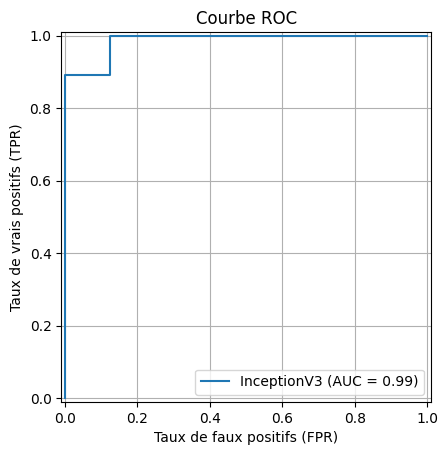

In [12]:
# Rapport de classification (précision, rappel, F1-score)
print("Classification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# Étape 6 : Calculer la courbe ROC et l'AUC
fpr, tpr, thresholds = roc_curve(y_true, y_pred[:, 1], pos_label=1)  # Utiliser la probabilité de la classe positive
roc_auc = auc(fpr, tpr)

# Étape 7 : Afficher la courbe ROC
plt.figure(figsize=(8, 6))
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, 
                estimator_name='InceptionV3').plot()
plt.title('Courbe ROC')
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.grid()
plt.show()

